# YOLO brain-tumor model comparison

Compare the nine latest 100-epoch runs: YOLOv8, YOLO11, and YOLO26 at nano, small, and medium scales. This notebook reads the saved validation metrics and training logs; it does not retrain models or require a GPU. The result-file registry deliberately excludes older runs so they cannot silently get mixed into the comparison.

Run from the project folder or `yolo_notebooks/`. Tables and figures are saved to `paper_figures/`.

> Research comparison only; not a diagnostic tool. The validation set is used for reported metrics, not an independent test set.

## 1. Load the pinned results

The paths below select one result JSON and one training log for each model. Root discovery works when the notebook is run from either the project root or its notebook folder.

In [4]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

CANDIDATES = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next((p for p in CANDIDATES if (p / "yolo_notebooks").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root (expected a yolo_notebooks folder in the current directory or a parent)."
    )

OUTPUT_DIR = ROOT / "paper_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

MODEL_SPECS = [
    {"model": "YOLOv8n", "family": "YOLOv8", "scale": "n",
     "result": "yolov8n_outputs_100ep_20261113/results_yolov8n.json",
     "run": "yolov8n_outputs_100ep_20261113/runs_100ep_workers0_20261113_batch16"},
    {"model": "YOLOv8s", "family": "YOLOv8", "scale": "s",
     "result": "yolov8_outputs/results_yolov8.json",
     "run": "yolov8_outputs/runs_100ep_workers0_20261113"},
    {"model": "YOLOv8m", "family": "YOLOv8", "scale": "m",
     "result": "yolov8m_outputs_100ep_20261113/results_yolov8m.json",
     "run": "yolov8m_outputs_100ep_20261113/runs_100ep_workers0_20261113_batch16"},
    {"model": "YOLO11n", "family": "YOLO11", "scale": "n",
     "result": "yolo11n_outputs/results_yolo11n_100ep.json",
     "run": "yolo11n_outputs/runs_100ep_20261113"},
    {"model": "YOLO11s", "family": "YOLO11", "scale": "s",
     "result": "yolo11_outputs/results_yolo11_100ep.json",
     "run": "yolo11_outputs/runs_100ep_20261112"},
    {"model": "YOLO11m", "family": "YOLO11", "scale": "m",
     "result": "yolo11m_outputs/results_yolo11m_100ep.json",
     "run": "yolo11m_outputs/runs_100ep_20261112"},
    {"model": "YOLO26n", "family": "YOLO26", "scale": "n",
     "result": "yolo26n_outputs_100ep_20261114/results_yolo26n.json",
     "run": "yolo26n_outputs_100ep_20261114/runs_100ep_workers0_20261114_batch16"},
    {"model": "YOLO26s", "family": "YOLO26", "scale": "s",
     "result": "yolo26_outputs/results_yolo26.json",
     "run": "yolo26_outputs/runs_100ep_workers0_20261113_batch16"},
    {"model": "YOLO26m", "family": "YOLO26", "scale": "m",
     "result": "yolo26m_outputs_100ep_20261114/results_yolo26m.json",
     "run": "yolo26m_outputs_100ep_20261114/runs_100ep_workers0_20261114_retry1_batch16"},
]

missing_results = [
    spec["result"] for spec in MODEL_SPECS if not (ROOT / spec["result"]).is_file()
]
if missing_results:
    raise FileNotFoundError(
        "Missing required result JSON files under the project root:\n- "
        + "\n- ".join(missing_results)
    )

RESULTS = {}
ROWS = []
for spec in MODEL_SPECS:
    result_path = ROOT / spec["result"]
    result = json.loads(result_path.read_text(encoding="utf-8"))
    metrics = result.get("metrics")
    if not isinstance(metrics, dict):
        raise ValueError(f"{result_path} has no metrics object.")
    if result.get("classes") != CLASSES:
        raise ValueError(
            f"{result_path} class order does not match the expected order: {CLASSES}"
        )
    for key in ("precision", "recall", "map50", "map50_95", "per_class_ap50"):
        if key not in metrics:
            raise ValueError(f"{result_path} is missing metrics.{key}.")
    if not all(name in metrics["per_class_ap50"] for name in CLASSES):
        raise ValueError(f"{result_path} is missing one or more per-class AP50 values.")

    RESULTS[spec["model"]] = result
    config = result.get("config") or {}
    training = result.get("training") or {}
    speed = result.get("speed_ms_per_image") or {}
    model_info = result.get("model_info") or {}
    row = {
        "Model": spec["model"],
        "Family": spec["family"],
        "Scale": spec["scale"],
        "Params (M)": model_info.get("params_m"),
        "GFLOPs": model_info.get("gflops"),
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "mAP@0.5": metrics["map50"],
        "mAP@0.5:0.95": metrics["map50_95"],
        "Inference (ms/image)": speed.get("inference"),
        "Epochs completed": training.get("epochs_completed"),
        "Best epoch": training.get("best_epoch"),
        "Image size": config.get("imgsz"),
        "Batch": config.get("batch"),
        "Seed": config.get("seed"),
        "Optimizer setting": config.get("optimizer"),
        "Workers": config.get("workers"),
        "Eval split": result.get("eval_split"),
    }
    row.update({
        f"AP50 {class_name}": metrics["per_class_ap50"][class_name]
        for class_name in CLASSES
    })
    ROWS.append(row)

print(f"Project root: {ROOT}")
print(f"Loaded {len(RESULTS)} model results.")

Project root: E:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo
Loaded 9 model results.


## 2. Verify the comparison protocol

A comparison is blocked unless all runs use the same image size, epoch budget, batch size, seed, validation split, and ordered class list. Worker count and optimizer settings are shown but not treated as identical training procedures; in particular, `optimizer="auto"` does not prove that different YOLO families used the same actual optimizer or recipe.

In [5]:
EXPECTED_CONFIG = {"imgsz": 640, "epochs": 100, "batch": 16, "seed": 42}
protocol_rows = []
protocol_issues = []

for spec in MODEL_SPECS:
    result = RESULTS[spec["model"]]
    config = result.get("config") or {}
    row = {
        "Model": spec["model"],
        **{key: config.get(key) for key in EXPECTED_CONFIG},
        "Optimizer setting": config.get("optimizer"),
        "Workers": config.get("workers"),
        "Eval split": result.get("eval_split"),
        "Classes match": result.get("classes") == CLASSES,
    }
    protocol_rows.append(row)
    for key, expected_value in EXPECTED_CONFIG.items():
        actual_value = config.get(key)
        if actual_value != expected_value:
            protocol_issues.append(
                f"{spec['model']}: config.{key}={actual_value!r}; expected {expected_value!r}"
            )
    if result.get("eval_split") != "val":
        protocol_issues.append(
            f"{spec['model']}: eval_split={result.get('eval_split')!r}; expected 'val'"
        )
    if result.get("classes") != CLASSES:
        protocol_issues.append(f"{spec['model']}: class list/order differs from the expected list")

protocol_table = pd.DataFrame(protocol_rows)
protocol_table

if protocol_issues:
    raise ValueError("Runs are not directly comparable:\n- " + "\n- ".join(protocol_issues))
print("Protocol check passed: all nine runs share the required evaluation settings.")

Protocol check passed: all nine runs share the required evaluation settings.


## 3. Metrics table and ranking

`mAP@0.5:0.95` is the primary ranking metric because it averages AP across stricter IoU thresholds. Precision, recall, per-class AP50, and recorded inference latency are included for context. Parameter and FLOP fields remain blank when the result files did not record them rather than being guessed.

In [6]:
comparison = pd.DataFrame(ROWS)
scale_order = pd.Categorical(comparison["Scale"], categories=["n", "s", "m"], ordered=True)
family_order = pd.Categorical(
    comparison["Family"], categories=["YOLOv8", "YOLO11", "YOLO26"], ordered=True
)
comparison = (
    comparison.assign(_scale_order=scale_order, _family_order=family_order)
    .sort_values(["_scale_order", "_family_order"])
    .drop(columns=["_scale_order", "_family_order"])
    .reset_index(drop=True)
)

csv_path = OUTPUT_DIR / "model_comparison_100ep.csv"
comparison.to_csv(csv_path, index=False)
display(comparison.round(4))

ranking = comparison.sort_values("mAP@0.5:0.95", ascending=False)[
    ["Model", "mAP@0.5:0.95", "mAP@0.5", "Precision", "Recall"]
].reset_index(drop=True)
display(ranking.round(4))
print(f"Saved metrics table: {csv_path}")

,Model,Family,Scale,Params (M),GFLOPs,Precision,Recall,mAP@0.5,mAP@0.5:0.95,Inference (ms/image),...,Image size,Batch,Seed,Optimizer setting,Workers,Eval split,AP50 Glioma,AP50 Meningioma,AP50 No Tumor,AP50 Pituitary
0,YOLOv8n,YOLOv8,n,None,None,0.9469,0.9501,0.9640,0.7789,4.006,...,640,16,42,auto,0,val,0.9325,0.9924,0.9950,0.9362
1,YOLO11n,YOLO11,n,None,None,0.9630,0.9437,0.9682,0.7822,3.209,...,640,16,42,auto,2,val,0.9333,0.9939,0.9950,0.9507
2,YOLO26n,YOLO26,n,None,None,0.9601,0.9412,0.9670,0.7757,4.329,...,640,16,42,auto,0,val,0.9320,0.9932,0.9947,0.9480
3,YOLOv8s,YOLOv8,s,None,None,0.9468,0.9437,0.9664,0.7838,5.884,...,640,16,42,auto,0,val,0.9457,0.9934,0.9949,0.9317
4,YOLO11s,YOLO11,s,None,None,0.9723,0.9245,0.9668,0.7832,5.981,...,640,16,42,auto,2,val,0.9433,0.9925,0.9949,0.9365
5,YOLO26s,YOLO26,s,None,None,0.9576,0.9507,0.9700,0.7848,6.332,...,640,16,42,auto,0,val,0.9373,0.9942,0.9950,0.9533
6,YOLOv8m,YOLOv8,m,None,None,0.9609,0.9262,0.9636,0.7797,13.522,...,640,16,42,auto,0,val,0.9258,0.9943,0.9848,0.9495
7,YOLO11m,YOLO11,m,None,None,0.9681,0.9344,0.9687,0.7862,13.569,...,640,16,42,auto,2,val,0.9385,0.9923,0.9945,0.9494
8,YOLO26m,YOLO26,m,None,None,0.9550,0.9444,0.9650,0.7794,13.398,...,640,16,42,auto,0,val,0.9270,0.9940,0.9950,0.9439


,Model,mAP@0.5:0.95,mAP@0.5,Precision,Recall
0,YOLO11m,0.7862,0.9687,0.9681,0.9344
1,YOLO26s,0.7848,0.9700,0.9576,0.9507
2,YOLOv8s,0.7838,0.9664,0.9468,0.9437
3,YOLO11s,0.7832,0.9668,0.9723,0.9245
4,YOLO11n,0.7822,0.9682,0.9630,0.9437
5,YOLOv8m,0.7797,0.9636,0.9609,0.9262
6,YOLO26m,0.7794,0.9650,0.9550,0.9444
7,YOLOv8n,0.7789,0.9640,0.9469,0.9501
8,YOLO26n,0.7757,0.9670,0.9601,0.9412


Saved metrics table: E:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo\paper_figures\model_comparison_100ep.csv


## 4. Visual comparisons

Compare the two mAP measures within each scale, inspect class-wise AP50, and view the recorded accuracy/latency trade-off. Inference latency is hardware- and runtime-dependent; treat it as an indicative measurement, not a standardized benchmark.

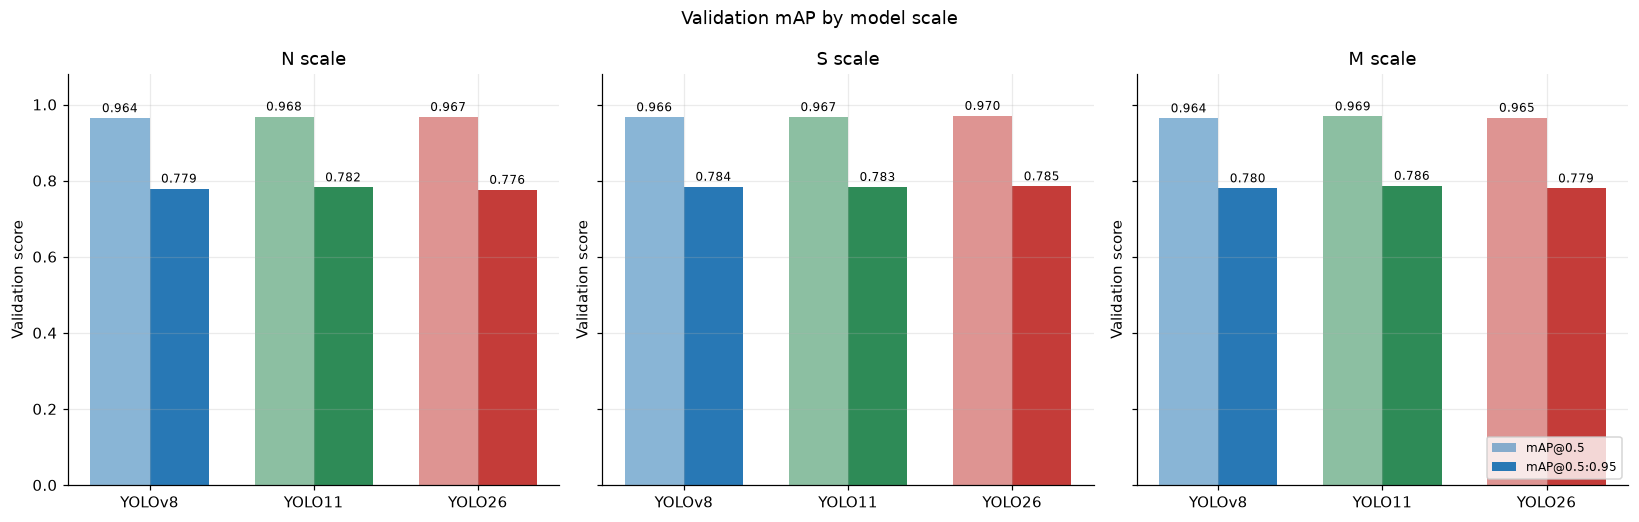

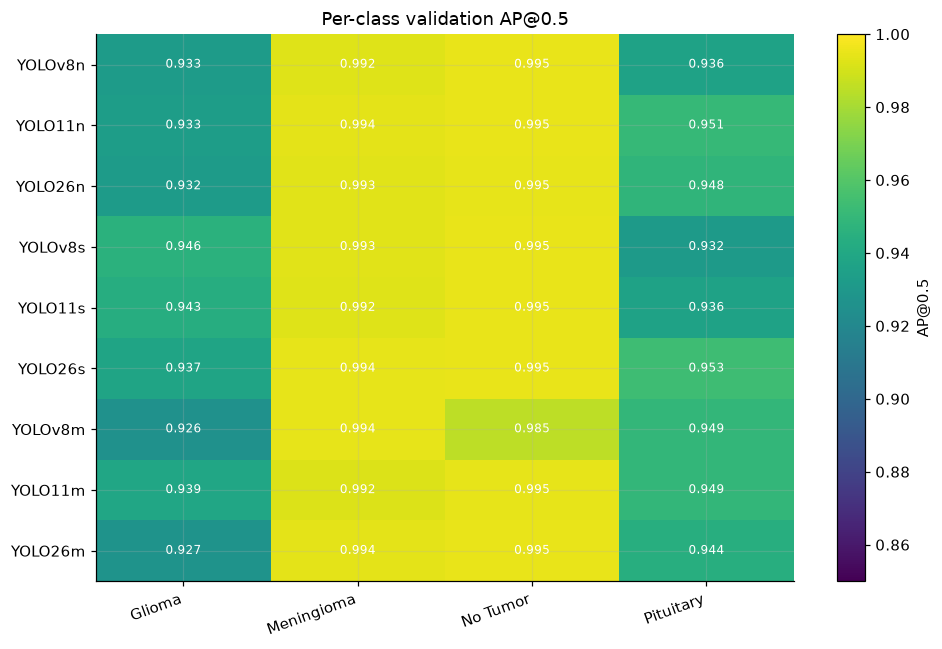

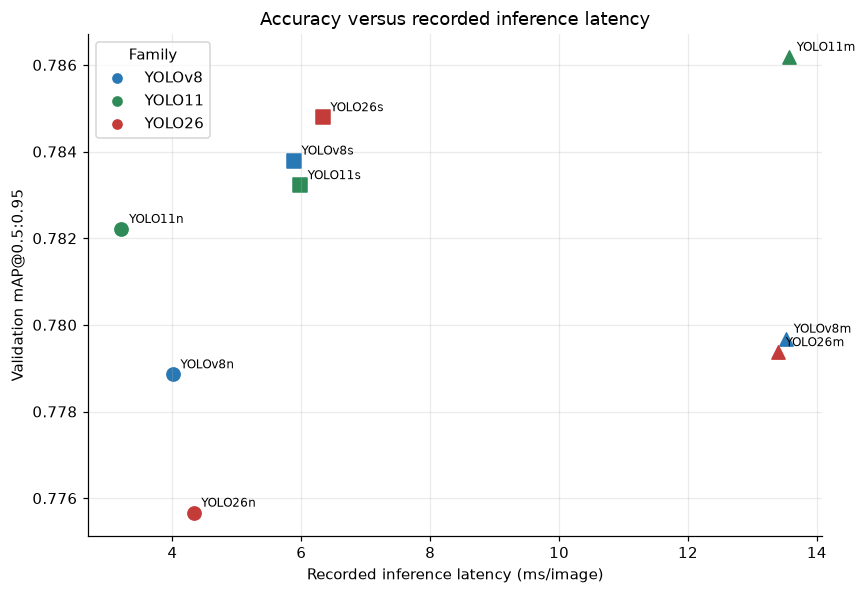

Saved comparison figures to E:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo\paper_figures


In [7]:
FAMILY_COLORS = {"YOLOv8": "#2878B5", "YOLO11": "#2E8B57", "YOLO26": "#C43C39"}
METRICS = ["mAP@0.5", "mAP@0.5:0.95"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, scale in zip(axes, ["n", "s", "m"]):
    subset = comparison[comparison["Scale"] == scale].copy()
    x = np.arange(len(subset))
    width = 0.36
    colors = [FAMILY_COLORS[family] for family in subset["Family"]]
    bars50 = ax.bar(x - width / 2, subset["mAP@0.5"], width, color=colors, alpha=0.55, label="mAP@0.5")
    bars95 = ax.bar(x + width / 2, subset["mAP@0.5:0.95"], width, color=colors, label="mAP@0.5:0.95")
    for bars in (bars50, bars95):
        ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8)
    ax.set_xticks(x, subset["Family"])
    ax.set_ylim(0, 1.08)
    ax.set_title(f"{scale.upper()} scale")
    ax.set_ylabel("Validation score")
axes[-1].legend(loc="lower right", fontsize=8)
fig.suptitle("Validation mAP by model scale")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "map_comparison_100ep.png", bbox_inches="tight")
plt.show()
plt.close(fig)

class_columns = [f"AP50 {class_name}" for class_name in CLASSES]
heat_data = comparison.set_index("Model")[class_columns].to_numpy(dtype=float)
fig, ax = plt.subplots(figsize=(9, 6))
image = ax.imshow(heat_data, cmap="viridis", vmin=0.85, vmax=1.0, aspect="auto")
ax.set_xticks(np.arange(len(CLASSES)), CLASSES, rotation=20, ha="right")
ax.set_yticks(np.arange(len(comparison)), comparison["Model"])
ax.set_title("Per-class validation AP@0.5")
for row_idx in range(heat_data.shape[0]):
    for col_idx in range(heat_data.shape[1]):
        ax.text(col_idx, row_idx, f"{heat_data[row_idx, col_idx]:.3f}",
                ha="center", va="center", fontsize=8, color="white")
fig.colorbar(image, ax=ax, label="AP@0.5")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "per_class_ap50_100ep.png", bbox_inches="tight")
plt.show()
plt.close(fig)

latency_data = comparison.dropna(subset=["Inference (ms/image)"])
scale_markers = {"n": "o", "s": "s", "m": "^"}
fig, ax = plt.subplots(figsize=(8, 5.5))
for _, row in latency_data.iterrows():
    ax.scatter(
        row["Inference (ms/image)"], row["mAP@0.5:0.95"],
        color=FAMILY_COLORS[row["Family"]], marker=scale_markers[row["Scale"]], s=75,
    )
    ax.annotate(row["Model"], (row["Inference (ms/image)"], row["mAP@0.5:0.95"]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
for family, color in FAMILY_COLORS.items():
    ax.scatter([], [], color=color, label=family)
ax.set_xlabel("Recorded inference latency (ms/image)")
ax.set_ylabel("Validation mAP@0.5:0.95")
ax.set_title("Accuracy versus recorded inference latency")
ax.legend(title="Family")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "accuracy_latency_100ep.png", bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved comparison figures to {OUTPUT_DIR}")

## 5. Validation training curves

Curves are drawn from each run's `results.csv`. These show learning trajectories, but do not replace repeated-seed evaluation or a held-out test set. Curves are compared at the same validation metric (`mAP@0.5:0.95`).

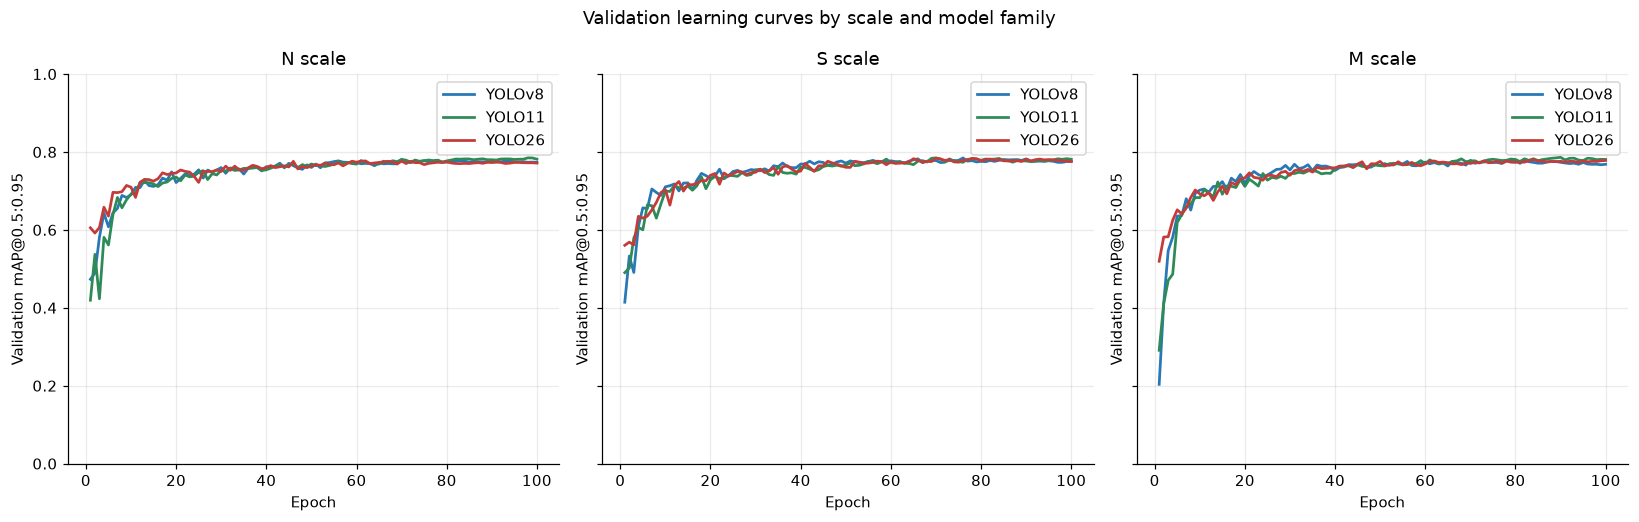

Saved validation curves to E:\brain-tumor-yolo-paper-rerun\brain-tumor-yolo\paper_figures\validation_curves_100ep.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, scale in zip(axes, ["n", "s", "m"]):
    for spec in MODEL_SPECS:
        if spec["scale"] != scale:
            continue
        csv_path = ROOT / spec["run"] / "results.csv"
        if not csv_path.is_file():
            raise FileNotFoundError(f"Missing training curve file for {spec['model']}: {csv_path}")
        curve = pd.read_csv(csv_path)
        curve.columns = [column.strip() for column in curve.columns]
        required = {"epoch", "metrics/mAP50-95(B)"}
        if not required.issubset(curve.columns):
            raise ValueError(f"{csv_path} must contain columns {sorted(required)}")
        ax.plot(
            curve["epoch"], curve["metrics/mAP50-95(B)"],
            color=FAMILY_COLORS[spec["family"]], linewidth=1.8, label=spec["family"],
        )
    ax.set_title(f"{scale.upper()} scale")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Validation mAP@0.5:0.95")
    ax.set_ylim(0, 1.0)
    ax.legend()

fig.suptitle("Validation learning curves by scale and model family")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_curves_100ep.png", bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved validation curves to {OUTPUT_DIR / 'validation_curves_100ep.png'}")

## Interpretation limits

- These are single-run validation results; no confidence intervals or significance tests are available.
- A validation split is not an independent test set. Avoid selecting a model and reporting this same split as unbiased final performance.
- Matching image size, epochs, batch size, seed, and split does not isolate architecture effects. Defaults, optimizers, losses, augmentation, and implementation details can differ across YOLO families.
- Latency depends on the device, software versions, and measurement conditions. Use a controlled benchmark before making deployment-speed claims.
- The metrics describe this dataset and task only and must not be interpreted as clinical performance.